In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/datossupermercado.csv', encoding='latin1')

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
df.shape

(9994, 21)

### 1. Diagnóstico Inicial de la Base de Datos
eliminar y transformar data set


In [ ]:
# 1. Definir las columnas a eliminar
columnas_a_remover = ['Row ID', 'Order ID', 'Customer ID', 'Product ID']

# Eliminar las columnas que estén presentes en el dataset
df_transformado = df.drop(columns=columnas_a_remover, errors='ignore')

# 2. Limpiar espacios en blanco en todas las columnas que tengan datos de tipo texto
for col in df_transformado.select_dtypes(include=['object']).columns:
    df_transformado[col] = df_transformado[col].astype(str).str.strip()

# Mostrar el resumen de las columnas restantes y la vista previa
print(f"Columnas restantes ({len(df_transformado.columns)}):\n", list(df_transformado.columns))
display(df_transformado.head())

Columnas restantes (17):
 ['Order Date', 'Ship Date', 'Ship Mode', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Order Date,Ship Date,Ship Mode,Customer Name,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,11/8/2016,11/11/2016,Second Class,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,11/8/2016,11/11/2016,Second Class,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,6/12/2016,6/16/2016,Second Class,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,10/11/2015,10/18/2015,Standard Class,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,10/11/2015,10/18/2015,Standard Class,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## Análisis Exploratorio de Datos (EDA)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar que las fechas tengan el formato correcto en el dataset transformado
df_transformado['Order Date'] = pd.to_datetime(df_transformado['Order Date'], errors='coerce')

# Configuración de estilo para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

### 1. ¿Cuáles son las categorías y subcategorías que generan más ventas y ganancias?

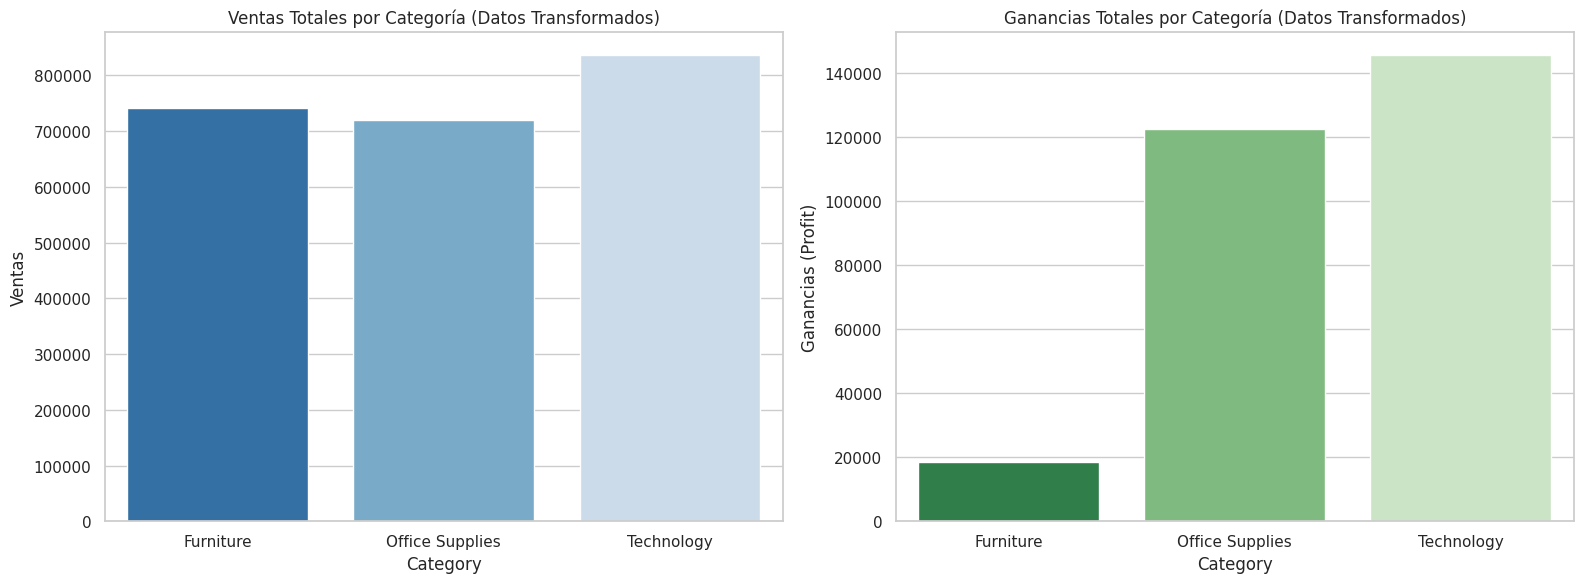

In [ ]:
# A grupar ventas y ganancias por Categoría usando el dataset transformado
cat_data = df_transformado.groupby('Category')[['Sales', 'Profit']].sum().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico de Ventas por Categoría
sns.barplot(data=cat_data, x='Category', y='Sales', ax=axes[0], palette='Blues_r', hue='Category', legend=False)
axes[0].set_title('Ventas Totales por Categoría (Datos Transformados)')
axes[0].set_ylabel('Ventas')

# Gráfico de Ganancias por Categoría
sns.barplot(data=cat_data, x='Category', y='Profit', ax=axes[1], palette='Greens_r', hue='Category', legend=False)
axes[1].set_title('Ganancias Totales por Categoría (Datos Transformados)')
axes[1].set_ylabel('Ganancias (Profit)')

plt.tight_layout()
plt.show()

### 2. Comportamiento de las Ventas a lo largo del tiempo

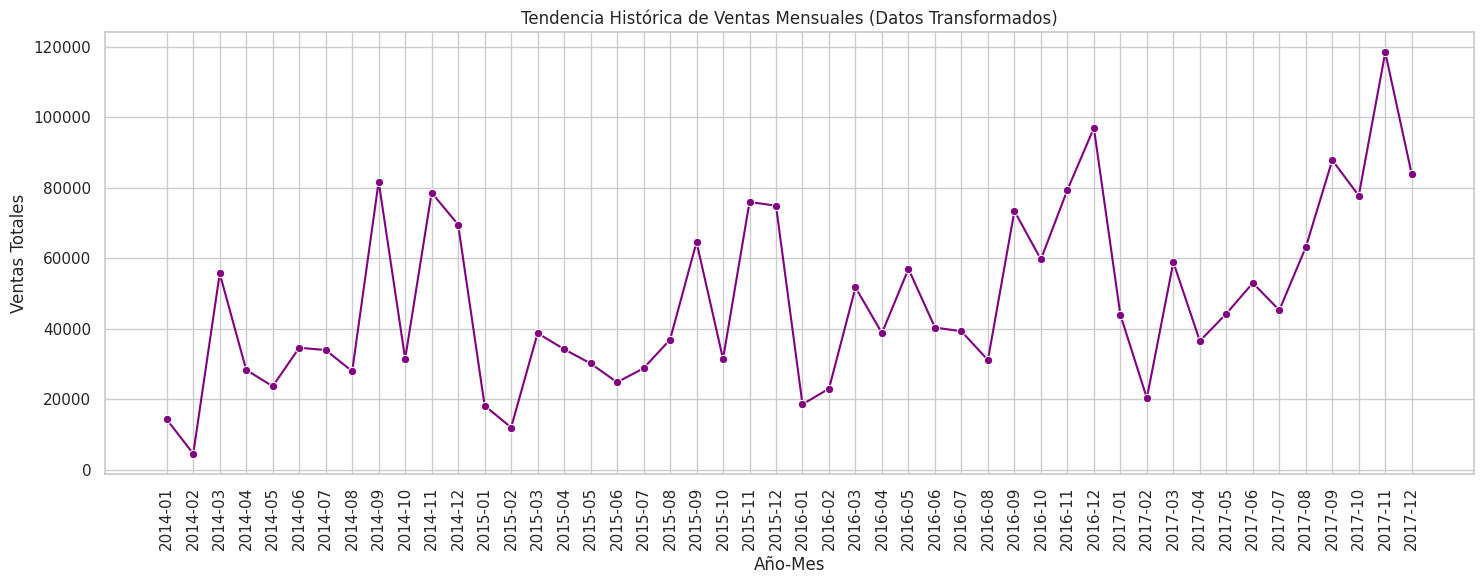

In [ ]:
# Agrupar ventas por mes y año usando el dataset transformado
test_time_df = df_transformado.copy()
test_time_df['YearMonth'] = test_time_df['Order Date'].dt.to_period('M')
time_data = test_time_df.groupby('YearMonth')['Sales'].sum().reset_index()
time_data['YearMonth'] = time_data['YearMonth'].astype(str)

plt.figure(figsize=(15, 6))
sns.lineplot(data=time_data, x='YearMonth', y='Sales', marker='o', color='purple')
plt.xticks(rotation=90)
plt.title('Tendencia Histórica de Ventas Mensuales (Datos Transformados)')
plt.xlabel('Año-Mes')
plt.ylabel('Ventas Totales')
plt.tight_layout()
plt.show()

#3PREGUNTAS DE NEGOCIO SQLREPORT

---



In [ ]:
import pandas as pd, sqlite3
from google.colab import files

files.upload()   # selecciona datossupermercado.csv

df = pd.read_csv('datossupermercado.csv', encoding='latin-1')
df.columns = df.columns.str.replace(' ', '_').str.replace('-', '_')
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='%m/%d/%Y').dt.strftime('%Y-%m-%d')
df['Ship_Date']  = pd.to_datetime(df['Ship_Date'],  format='%m/%d/%Y').dt.strftime('%Y-%m-%d')

conn = sqlite3.connect('supermercado.db')
df.to_sql('ventas', conn, if_exists='replace', index=False)

print(df.shape)   # debe mostrar (9994, 21)

Saving datossupermercado.csv to datossupermercado.csv
(9994, 21)


#¿Qué segmento de clientes aporta más valor?
Compara consumidor, corporativo en casa por ventas, ganancia y frecuencia de compra. Usa Segmento, Cliente, Ventas y Ganancia;se usaría para las decisiones posibles: enfocar el marketing.



---



In [ ]:
q1 = """
SELECT Segment,
       COUNT(DISTINCT Customer_ID) AS clientes,
       ROUND(SUM(Sales),2) AS ventas,
       ROUND(SUM(Profit),2) AS utilidad,
       ROUND(100.0*SUM(Profit)/SUM(Sales),2) AS margen_pct,
       ROUND(SUM(Profit)/COUNT(DISTINCT Customer_ID),2) AS utilidad_por_cliente
FROM ventas
GROUP BY Segment
ORDER BY utilidad DESC;
"""
pd.read_sql(q1, conn)

,Segment,clientes,ventas,utilidad,margen_pct,utilidad_por_cliente
0,Consumer,409,1161401.34,134119.21,11.55,327.92
1,Corporate,236,706146.37,91979.13,13.03,389.74
2,Home Office,148,429653.15,60298.68,14.03,407.42


#¿Qué regiones o estados son más rentables y cuáles tienen mejor desempeño que otros?
Sirve para ver dónde invertir o reforzar la operación. Usa Región, Estado, Ventas y Ganancia.   


---



In [ ]:
q2a = """
SELECT Region,
       ROUND(SUM(Sales),2) AS ventas,
       ROUND(SUM(Profit),2) AS utilidad,
       ROUND(100.0*SUM(Profit)/SUM(Sales),2) AS margen_pct,
       ROUND(AVG(Discount),3) AS desc_prom
FROM ventas
GROUP BY Region
ORDER BY utilidad DESC;
"""
q2b = """
SELECT State,
       ROUND(SUM(Sales),2) AS ventas,
       ROUND(SUM(Profit),2) AS utilidad,
       ROUND(100.0*SUM(Profit)/SUM(Sales),2) AS margen_pct,
       ROUND(AVG(Discount),3) AS desc_prom
FROM ventas
GROUP BY State
ORDER BY utilidad {orden}
LIMIT 10;
"""
display(pd.read_sql(q2a, conn))                        # por región
display(pd.read_sql(q2b.format(orden='DESC'), conn))   # 10 mejores estados
display(pd.read_sql(q2b.format(orden='ASC'), conn))    # 10 peores estados

,Region,ventas,utilidad,margen_pct,desc_prom
0,West,725457.82,108418.45,14.94,0.109
1,East,678781.24,91522.78,13.48,0.145
2,South,391721.91,46749.43,11.93,0.147
3,Central,501239.89,39706.36,7.92,0.240


,State,ventas,utilidad,margen_pct,desc_prom
0,California,457687.63,76381.39,16.69,0.073
1,New York,310876.27,74038.55,23.82,0.055
2,Washington,138641.27,33402.65,24.09,0.064
3,Michigan,76269.61,24463.19,32.07,0.007
4,Virginia,70636.72,18597.95,26.33,0.000
5,Indiana,53555.36,18382.94,34.33,0.000
6,Georgia,49095.84,16250.04,33.10,0.000
7,Kentucky,36591.75,11199.70,30.61,0.000
8,Minnesota,29863.15,10823.19,36.24,0.000
9,Delaware,27451.07,9977.37,36.35,0.006


,State,ventas,utilidad,margen_pct,desc_prom
0,Texas,170188.05,-25729.36,-15.12,0.370
1,Ohio,78258.14,-16971.38,-21.69,0.325
2,Pennsylvania,116511.91,-15559.96,-13.35,0.329
3,Illinois,80166.10,-12607.89,-15.73,0.390
4,North Carolina,55603.16,-7490.91,-13.47,0.284
5,Colorado,32108.12,-6527.86,-20.33,0.316
6,Tennessee,30661.87,-5341.69,-17.42,0.291
7,Arizona,35282.00,-3427.92,-9.72,0.304
8,Florida,89473.71,-3399.30,-3.80,0.299
9,Oregon,17431.15,-1190.47,-6.83,0.289


#¿Los descuentos están afectando la rentabilidad?
Compara el nivel de descuento con la ganancia por pedido y busca a partir de qué porcentaje empiezan las pérdidas. Usa Descuento, Ventas y Ganancia. Decisión posible: poner un tope a los descuentos.


---



In [ ]:
 q3 = """
SELECT CASE WHEN Discount = 0     THEN '1. Sin descuento'
            WHEN Discount <= 0.2  THEN '2. 1%-20%'
            WHEN Discount <= 0.4  THEN '3. 21%-40%'
            ELSE '4. Más de 40%' END AS rango,
       COUNT(*) AS lineas,
       ROUND(SUM(Sales),2) AS ventas,
       ROUND(SUM(Profit),2) AS utilidad,
       ROUND(100.0*SUM(Profit)/SUM(Sales),2) AS margen_pct,
       ROUND(100.0*SUM(CASE WHEN Profit<0 THEN 1 ELSE 0 END)/COUNT(*),1) AS pct_con_perdida
FROM ventas
GROUP BY rango
ORDER BY rango;
"""
pd.read_sql(q3, conn)

,rango,lineas,ventas,utilidad,margen_pct,pct_con_perdida
0,1. Sin descuento,4798,1087908.47,320987.60,29.51,0.0
1,2. 1%-20%,3803,846522.24,100785.47,11.91,13.8
2,3. 21%-40%,460,234137.90,-35817.47,-15.30,90.2
3,4. Más de 40%,933,128632.25,-99558.59,-77.40,100.0
